In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [19]:
class0 = np.random.randn(100, 2) * 2 + np.array([2,2])
class1 = np.random.randn(50, 2) * 2 + np.array([6.6])

X = np.vstack((class0, class1))
y = np.hstack((np.zeros(100), np.ones(50)))

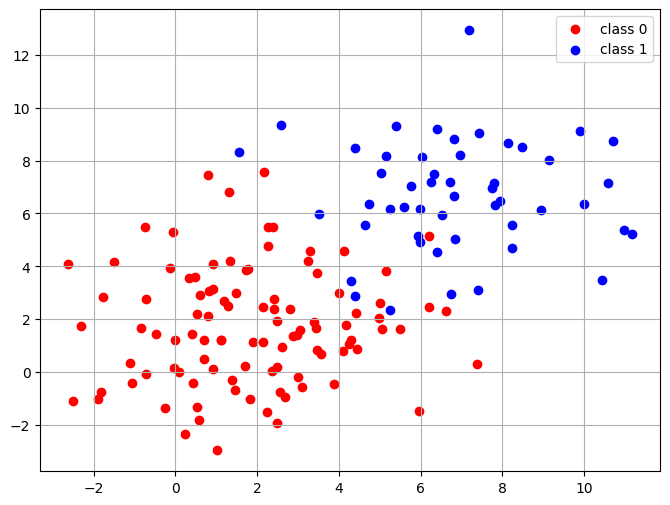

In [20]:
plt.figure(figsize=(8,6))
plt.scatter(X[:100, 0], X[:100, 1], color='red', label='class 0')
plt.scatter(X[100:, 0], X[100:, 1], color='blue', label='class 1')
plt.legend()
plt.grid()
plt.show()

In [22]:
X.shape

(150, 2)

In [23]:
y.shape

(150,)

In [21]:
def sigmoid(z):
  return 1 / (1 + np.exp(-z))

In [24]:
def logistic_regression(X, y, lr, iter):
  samples, features = X.shape
  weigths = np.zeros(features)
  bias = 0.0
  epsilon = 1e-15
  losses = []
  for i in range(iter):
    z = np.dot(X, weigths) + bias
    y_pred = sigmoid(z)
    loss = -np.sum(y * np.log(y_pred + epsilon) + (1-y) * np.log (1 - y_pred + epsilon)) / samples
    losses.append(loss)
    dw = np.dot(X.T, (y_pred - y)) / samples
    db = np.sum(y_pred - y) / samples
    weigths -= lr * dw
    bias -= lr * db
  return weigths, bias, losses


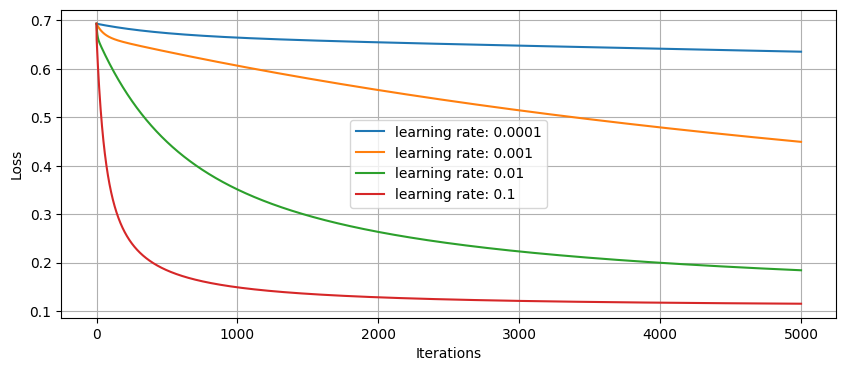

In [29]:
learning_rates = [0.0001, 0.001, 0.01, 0.1]
plt.figure(figsize=(10,4))

for lr in learning_rates:
  weigths, bias, losses = logistic_regression(X, y, lr, 5000)
  plt.plot(losses, label=f'learning rate: {lr}')

plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [31]:
# best learning rate
weights, bias, losses = logistic_regression(X, y, 0.1, 5000)
print(f"Final weight: {weights}")
print(f"Final bias: {bias}")
print(f"Final loss: {losses[-1]}")

Final weight: [0.99330943 0.8949599 ]
Final bias: -8.70933241951497
Final loss: 0.11527857677427882


In [32]:
z = np.dot(X, weights) + bias
y_pred = sigmoid(z)
y_pred = (y_pred >=0.5).astype('int')

In [39]:
print("Actual | Predicted")
print("==================")

for i in range(len(y)):
  print(f"{int(y[i])}\t |\t {y_pred[i]}")

Actual | Predicted
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 1
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 1
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
0	 |	 0
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	 1
1	 |	

In [42]:
TP = TN = FP = FN = 0

for i in range(len(y)):
  if y[i]==1 and y_pred[i]==1:
    TP += 1
  elif y[i]==0 and y_pred[i]==1:
    FP += 1
  elif y[i]==1 and y_pred[i]==0:
    FN += 1
  elif y[i]==0 and y_pred[i]==0:
    TN += 1

confusion_matrix = np.array([[TP, FP], [FN, TN]])
print(f"Confusion Matrix: \n {confusion_matrix}")


Confusion Matrix: 
 [[47  2]
 [ 3 98]]


In [44]:
accuracy = (TP+TN) / (TP+TN+FN+FP)
precision = TP / (TP+FP) if (TP+FP) > 0 else 0
recall = TP / (TP+FN) if (TP+FN) > 0 else 0
f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1_score:.4f}")

Accuracy: 0.9667
Precision: 0.9592
Recall: 0.9400
F1 Score: 0.9495
